# Classificação de pneumonia em radiografias de tórax
**Tech Challenge — Visão Computacional | FIAP**

**Equipe:** Arnold (RM 377310), Bhendon (RM 377937), Laercio (RM 378529), Marcos (RM 378872) e Victor (RM 378625).

### Objetivo
Desenvolver e comparar **duas redes neurais convolucionais (CNNs)** para classificar radiografias pediátricas de tórax em **NORMAL (0)** ou **PNEUMONIA (1)**. Além do desempenho, investigamos possíveis dificuldades de **generalização** e a influência do pré-processamento das imagens.

### Informações
1. Neste notebook está sendo usado o kernel **Python 3.12 (Pneumonia - TensorFlow)**.
2. A opção **`TREINAR_MODELOS = False`** carrega os modelos `.keras` já treinados; use `True` apenas para refazer o treinamento.

**Organização dos dados:** usamos as imagens de `train` para criar novos conjuntos de treino e validação, agrupando por paciente. A validação original, com apenas 16 imagens, não foi utilizada. A partição original `test` foi reservada para avaliação e posteriormente examinada em análises exploratórias; por isso, não serve como teste independente para futuras escolhas de modelo.

> **Escopo:** experimento acadêmico. Os resultados não constituem validação clínica nem autorizam uso para diagnóstico médico.


In [166]:
# Configuração portátil: sem dependência do Google Colab ou Google Drive
from pathlib import Path

BASE_DIR = Path.cwd().resolve()
DRIVE_DIR = BASE_DIR  # Alias para manter a compatibilidade com as demais células
ZIP_PATH = BASE_DIR / "chest_xray.zip"
EXTRACT_DIR = BASE_DIR / "dataset"
MODELOS_DIR = BASE_DIR / "modelos"
SPLIT_DIR = BASE_DIR / "splits"
TREINAR_MODELOS = False  # True: refaz o treinamento; False: carrega os .keras existentes

MODELOS_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
print("Diretório de trabalho:", BASE_DIR)
print("ZIP disponível:", ZIP_PATH.exists())
print("Dataset extraído:", (EXTRACT_DIR / "chest_xray").exists())
print("Treinamento habilitado:", TREINAR_MODELOS)

Diretório de trabalho: /workspace/notebooks/pneumonia
ZIP disponível: True
Dataset extraído: True
Treinamento habilitado: False


Diretório de trabalho: /workspace/notebooks/pneumonia
ZIP disponível: True
Dataset extraído: True
Treinamento habilitado: False


In [167]:
from pathlib import Path
import zipfile

DATASET_DIR = EXTRACT_DIR / "chest_xray"
if not DATASET_DIR.exists():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            f"Dataset não encontrado. Coloque {ZIP_PATH.name} em {BASE_DIR} "
            f"ou extraia as imagens em {DATASET_DIR}."
        )
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)
    print("Dataset extraído em:", DATASET_DIR)
else:
    print("Dataset já extraído:", DATASET_DIR)

Dataset já extraído: /workspace/notebooks/pneumonia/dataset/chest_xray


Dataset já extraído: /workspace/notebooks/pneumonia/dataset/chest_xray


## 1. Conhecendo o conjunto de dados

Começamos verificando a estrutura das pastas `train`, `val` e `test` e contando as imagens das classes **NORMAL** e **PNEUMONIA**. Essa inspeção permite identificar o **desbalanceamento entre classes** e entender quais dados estão disponíveis para cada etapa.

Também observamos nomes de arquivos, pois eles ajudam a identificar diferentes imagens pertencentes a um mesmo paciente.


In [168]:
DATASET_DIR = EXTRACT_DIR / "chest_xray"

for conjunto in ["train", "val", "test"]:
    for classe in ["NORMAL", "PNEUMONIA"]:

        pasta = DATASET_DIR / conjunto / classe

        quantidade = len(list(pasta.glob("*.jpeg")))

        print(f"{conjunto:5} | {classe:9} | {quantidade:4} imagens")

train | NORMAL    | 1341 imagens
train | PNEUMONIA | 3875 imagens
val   | NORMAL    |    8 imagens
val   | PNEUMONIA |    8 imagens
test  | NORMAL    |  234 imagens
test  | PNEUMONIA |  390 imagens


train | NORMAL    | 1341 imagens
train | PNEUMONIA | 3875 imagens
val   | NORMAL    |    8 imagens
val   | PNEUMONIA |    8 imagens
test  | NORMAL    |  234 imagens
test  | PNEUMONIA |  390 imagens


In [169]:
from pathlib import Path

for classe in ["NORMAL", "PNEUMONIA"]:

    pasta = DATASET_DIR / "train" / classe

    arquivos = sorted(pasta.glob("*.jpeg"))

    print(f"\nClasse: {classe}")
    print("-" * 50)

    for arquivo in arquivos[:10]:
        print(arquivo.name)


Classe: NORMAL
--------------------------------------------------
IM-0115-0001.jpeg
IM-0117-0001.jpeg
IM-0119-0001.jpeg
IM-0122-0001.jpeg
IM-0125-0001.jpeg
IM-0127-0001.jpeg
IM-0128-0001.jpeg
IM-0129-0001.jpeg
IM-0131-0001.jpeg
IM-0133-0001.jpeg

Classe: PNEUMONIA
--------------------------------------------------
person1000_bacteria_2931.jpeg
person1000_virus_1681.jpeg
person1001_bacteria_2932.jpeg
person1002_bacteria_2933.jpeg
person1003_bacteria_2934.jpeg
person1003_virus_1685.jpeg
person1004_bacteria_2935.jpeg
person1004_virus_1686.jpeg
person1005_bacteria_2936.jpeg
person1005_virus_1688.jpeg



Classe: NORMAL
--------------------------------------------------
IM-0115-0001.jpeg
IM-0117-0001.jpeg
IM-0119-0001.jpeg
IM-0122-0001.jpeg
IM-0125-0001.jpeg
IM-0127-0001.jpeg
IM-0128-0001.jpeg
IM-0129-0001.jpeg
IM-0131-0001.jpeg
IM-0133-0001.jpeg

Classe: PNEUMONIA
--------------------------------------------------
person1000_bacteria_2931.jpeg
person1000_virus_1681.jpeg
person1001_bacteria_2932.jpeg
person1002_bacteria_2933.jpeg
person1003_bacteria_2934.jpeg
person1003_virus_1685.jpeg
person1004_bacteria_2935.jpeg
person1004_virus_1686.jpeg
person1005_bacteria_2936.jpeg
person1005_virus_1688.jpeg


## 2. Separação de treino e validação por paciente

Para avaliar o modelo de forma mais confiável, identificamos os pacientes a partir dos nomes dos arquivos e usamos **`GroupShuffleSplit`**, separadamente por classe, para criar treino e validação a partir do `train` original.

**Por que isso importa?** Se radiografias do mesmo paciente aparecessem nos dois conjuntos, a rede poderia reconhecer características daquele paciente e apresentar métricas artificialmente elevadas. A célula de conferência verifica que **não há pacientes compartilhados** entre as duas partições. Salvamos também os CSVs dos splits para documentar a divisão utilizada.


In [170]:
from collections import Counter
import re

def identificar_paciente(nome_arquivo, classe):

    if classe == "PNEUMONIA":
        resultado = re.match(r"^(person\d+)_", nome_arquivo)

    else:
        resultado = re.match(r"^((?:NORMAL2-)?IM-\d+)-", nome_arquivo)

    if resultado:
        return resultado.group(1)

    return None


for classe in ["NORMAL", "PNEUMONIA"]:

    pasta = DATASET_DIR / "train" / classe
    arquivos = list(pasta.glob("*.jpeg"))

    pacientes = [
        identificar_paciente(arquivo.name, classe)
        for arquivo in arquivos
    ]

    identificados = [p for p in pacientes if p is not None]

    contagem = Counter(identificados)

    print(f"\nClasse: {classe}")
    print("-" * 50)

    print("Total de imagens:", len(arquivos))
    print("Imagens com identificador:", len(identificados))
    print("Imagens sem identificador:", pacientes.count(None))
    print("Identificadores diferentes:", len(contagem))

    print("\nExemplos de identificadores com múltiplas imagens:")

    for paciente, quantidade in contagem.most_common(10):
        if quantidade > 1:
            print(f"{paciente}: {quantidade} imagens")

    sem_identificador = [
        arquivo.name
        for arquivo, paciente in zip(arquivos, pacientes)
        if paciente is None
    ]

    if sem_identificador:
        print("\nExemplos sem identificador:")
        print(sem_identificador[:10])


Classe: NORMAL
--------------------------------------------------
Total de imagens: 1341
Imagens com identificador: 1341
Imagens sem identificador: 0
Identificadores diferentes: 1211

Exemplos de identificadores com múltiplas imagens:
IM-0629: 4 imagens
IM-0523: 4 imagens
IM-0553: 4 imagens
IM-0525: 3 imagens
NORMAL2-IM-0983: 3 imagens
IM-0551: 3 imagens
IM-0650: 3 imagens
NORMAL2-IM-1258: 3 imagens
IM-0549: 3 imagens
NORMAL2-IM-0851: 3 imagens

Classe: PNEUMONIA
--------------------------------------------------
Total de imagens: 3875
Imagens com identificador: 3875
Imagens sem identificador: 0
Identificadores diferentes: 1635

Exemplos de identificadores com múltiplas imagens:
person23: 30 imagens
person441: 18 imagens
person124: 16 imagens
person1320: 14 imagens
person30: 14 imagens
person348: 13 imagens
person266: 12 imagens
person281: 12 imagens
person326: 12 imagens
person1411: 12 imagens



Classe: NORMAL
--------------------------------------------------
Total de imagens: 1341
Imagens com identificador: 1341
Imagens sem identificador: 0
Identificadores diferentes: 1211

Exemplos de identificadores com múltiplas imagens:
IM-0629: 4 imagens
IM-0523: 4 imagens
IM-0553: 4 imagens
IM-0525: 3 imagens
NORMAL2-IM-0983: 3 imagens
IM-0551: 3 imagens
IM-0650: 3 imagens
NORMAL2-IM-1258: 3 imagens
IM-0549: 3 imagens
NORMAL2-IM-0851: 3 imagens

Classe: PNEUMONIA
--------------------------------------------------
Total de imagens: 3875
Imagens com identificador: 3875
Imagens sem identificador: 0
Identificadores diferentes: 1635

Exemplos de identificadores com múltiplas imagens:
person23: 30 imagens
person441: 18 imagens
person124: 16 imagens
person1320: 14 imagens
person30: 14 imagens
person348: 13 imagens
person266: 12 imagens
person281: 12 imagens
person326: 12 imagens
person1411: 12 imagens


In [171]:
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

registros = []

# Criar uma lista com todas as imagens de treinamento
for classe in ["NORMAL", "PNEUMONIA"]:

    pasta = DATASET_DIR / "train" / classe

    for arquivo in pasta.glob("*.jpeg"):

        paciente = identificar_paciente(
            arquivo.name,
            classe
        )

        registros.append({
            "arquivo": str(arquivo),
            "classe": classe,
            "paciente": paciente
        })

# Criar DataFrame
df = pd.DataFrame(registros)

print("Total de imagens:", len(df))

display(df.head())

Total de imagens: 5216


,arquivo,classe,paciente
0,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,IM-0525
1,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,IM-0381
2,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,NORMAL2-IM-0536
3,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,NORMAL2-IM-0464
4,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,IM-0599


Total de imagens: 5216


,arquivo,classe,paciente
0,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,IM-0525
1,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,IM-0381
2,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,NORMAL2-IM-0536
3,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,NORMAL2-IM-0464
4,/workspace/notebooks/pneumonia/dataset/chest_x...,NORMAL,IM-0599


In [172]:
train_partes = []
val_partes = []

for classe in ["NORMAL", "PNEUMONIA"]:

    df_classe = df[df["classe"] == classe].copy()

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=42
    )

    train_idx, val_idx = next(
        splitter.split(
            df_classe,
            groups=df_classe["paciente"]
        )
    )

    train_partes.append(df_classe.iloc[train_idx])
    val_partes.append(df_classe.iloc[val_idx])

# Reunir as duas classes
df_train = pd.concat(train_partes, ignore_index=True)
df_val = pd.concat(val_partes, ignore_index=True)

print("Treinamento:", len(df_train))
print("Validação:", len(df_val))

Treinamento: 4158
Validação: 1058


Treinamento: 4158
Validação: 1058


In [173]:
pacientes_train = set(df_train["paciente"])
pacientes_val = set(df_val["paciente"])

pacientes_repetidos = pacientes_train.intersection(
    pacientes_val
)

print("Identificadores presentes nos dois conjuntos:",
      len(pacientes_repetidos))

print("\nDistribuição do treinamento:")
print(df_train["classe"].value_counts())

print("\nDistribuição da validação:")
print(df_val["classe"].value_counts())

Identificadores presentes nos dois conjuntos: 0

Distribuição do treinamento:
classe
PNEUMONIA    3087
NORMAL       1071
Name: count, dtype: int64

Distribuição da validação:
classe
PNEUMONIA    788
NORMAL       270
Name: count, dtype: int64


Identificadores presentes nos dois conjuntos: 0

Distribuição do treinamento:
classe
PNEUMONIA    3087
NORMAL       1071
Name: count, dtype: int64

Distribuição da validação:
classe
PNEUMONIA    788
NORMAL       270
Name: count, dtype: int64


## 3. Preparação das imagens — CNN 1

As radiografias são lidas em **tons de cinza**, normalizadas para valores entre **0 e 1** e convertidas para **224 × 224 pixels**. Na primeira CNN, usamos `tf.image.resize_with_pad`: a imagem mantém sua proporção original e recebe preenchimento preto quando necessário.

Em seguida, montamos os conjuntos de dados com `tf.data`, em lotes de **16 imagens**, e inspecionamos exemplos e dimensões para confirmar que a entrada está correta.

**Ponto de atenção:** preservar a proporção evita distorções, mas introduz bordas de preenchimento que também podem ser percebidas pela rede.


In [174]:
import tensorflow as tf

IMG_SIZE = 224

def preprocessar_imagem(caminho, classe):

    # Ler o arquivo
    imagem = tf.io.read_file(caminho)

    # Decodificar JPEG em escala de cinza
    imagem = tf.io.decode_jpeg(
        imagem,
        channels=1
    )

    # Converter os pixels para float32 entre 0 e 1
    imagem = tf.image.convert_image_dtype(
        imagem,
        tf.float32
    )

    # Redimensionar preservando a proporção
    imagem = tf.image.resize_with_pad(
        imagem,
        IMG_SIZE,
        IMG_SIZE
    )

    return imagem, classe

Formato: (224, 224, 1)
Tipo: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 1.0
Classe: 0


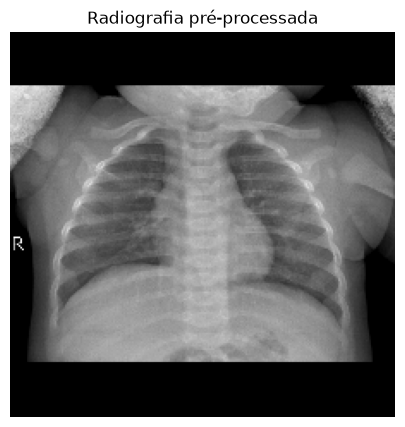

Formato: (224, 224, 1)
Tipo: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 1.0
Classe: 0


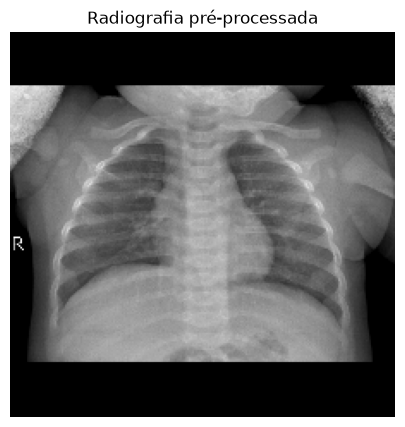

In [175]:
import matplotlib.pyplot as plt

# Selecionar uma imagem do treinamento
caminho = df_train.iloc[0]["arquivo"]

# Classe: 0 = NORMAL, 1 = PNEUMONIA
classe = 0 if df_train.iloc[0]["classe"] == "NORMAL" else 1

# Processar a imagem
imagem, rotulo = preprocessar_imagem(
    caminho,
    classe
)

print("Formato:", imagem.shape)
print("Tipo:", imagem.dtype)
print("Valor mínimo:", tf.reduce_min(imagem).numpy())
print("Valor máximo:", tf.reduce_max(imagem).numpy())
print("Classe:", rotulo)

# Exibir a imagem
plt.figure(figsize=(5, 5))
plt.imshow(imagem.numpy().squeeze(), cmap="gray")
plt.title("Radiografia pré-processada")
plt.axis("off")
plt.show()

In [176]:
import tensorflow as tf

BATCH_SIZE = 16

def criar_dataset(df, treinamento=False):

    # Caminhos das imagens
    caminhos = df["arquivo"].values

    # Converter classes em números
    classes = df["classe"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).values.astype("float32")

    # Criar dataset
    dataset = tf.data.Dataset.from_tensor_slices(
        (caminhos, classes)
    )

    # Embaralhar somente o treinamento
    if treinamento:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42
        )

    # Aplicar o pré-processamento
    dataset = dataset.map(
        preprocessar_imagem,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Organizar em batches
    dataset = dataset.batch(BATCH_SIZE)

    # Preparar os próximos batches antecipadamente
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Criar os conjuntos
train_ds = criar_dataset(df_train, treinamento=True)
val_ds = criar_dataset(df_val)

print("Datasets criados com sucesso!")

Datasets criados com sucesso!


Datasets criados com sucesso!


In [177]:
for imagens, classes in train_ds.take(1):

    print("Formato das imagens:", imagens.shape)
    print("Formato das classes:", classes.shape)

    print("\nClasses do primeiro batch:")
    print(classes.numpy())

    print("\nValor mínimo:", tf.reduce_min(imagens).numpy())
    print("Valor máximo:", tf.reduce_max(imagens).numpy())

Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)

Classes do primeiro batch:
[1. 1. 1. 1. 1. 0. 1. 1. 0. 0. 1. 0. 1. 1. 0. 1.]

Valor mínimo: 0.0
Valor máximo: 1.0


Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)

Classes do primeiro batch:
[1. 1. 1. 1. 1. 0. 1. 1. 0. 0. 1. 0. 1. 1. 0. 1.]

Valor mínimo: 0.0
Valor máximo: 1.0


In [178]:
# Diretório para armazenar a divisão do dataset
SPLIT_DIR = DRIVE_DIR / "splits"

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Salvar treinamento e validação
df_train.to_csv(
    SPLIT_DIR / "train.csv",
    index=False
)

df_val.to_csv(
    SPLIT_DIR / "val.csv",
    index=False
)

print("Divisão salva com sucesso!")
print("Treinamento:", len(df_train))
print("Validação:", len(df_val))
print("Local:", SPLIT_DIR)

Divisão salva com sucesso!
Treinamento: 4158
Validação: 1058
Local: /workspace/notebooks/pneumonia/splits


Divisão salva com sucesso!
Treinamento: 4158
Validação: 1058
Local: /workspace/notebooks/pneumonia/splits


## 4. Construção e treinamento — CNN 1

A primeira CNN utiliza **três blocos convolucionais** para extrair padrões visuais, seguidos de *global average pooling*, camada densa, *dropout* e uma saída **sigmoide** para classificação binária.

O treinamento foi configurado com **Adam**, perda `binary_crossentropy` e métricas como acurácia, precisão, *recall* e AUC. Aplicamos **pesos de classe** para compensar a maior quantidade de imagens com pneumonia.

Os callbacks **`ModelCheckpoint`** e **`EarlyStopping`** guardam o modelo com menor perda de validação e interrompem o treinamento quando não há melhora. Com `TREINAR_MODELOS = False`, carregamos diretamente `modelos/cnn_pneumonia_best.keras`; nesse modo, não são gerados novos gráficos de histórico de treinamento.


In [179]:
from tensorflow.keras import layers, models

modelo = models.Sequential([

    layers.Input(shape=(224, 224, 1)),

    # Primeiro bloco convolucional
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Segundo bloco convolucional
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Terceiro bloco convolucional
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Transformar mapas de características em vetor
    layers.GlobalAveragePooling2D(),

    # Camada de classificação
    layers.Dense(64, activation="relu"),

    # Regularização
    layers.Dropout(0.3),

    # Saída binária
    layers.Dense(1, activation="sigmoid")

])

modelo.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [180]:
import tensorflow as tf

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("CNN compilada com sucesso!")

CNN compilada com sucesso!


CNN compilada com sucesso!


In [181]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Converter os rótulos para números
y_train = df_train["classe"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).values

# Calcular os pesos
pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weights = {
    0: float(pesos[0]),
    1: float(pesos[1])
}

print("Pesos das classes:")
print(f"NORMAL (0): {class_weights[0]:.4f}")
print(f"PNEUMONIA (1): {class_weights[1]:.4f}")

Pesos das classes:
NORMAL (0): 1.9412
PNEUMONIA (1): 0.6735


Pesos das classes:
NORMAL (0): 1.9412
PNEUMONIA (1): 0.6735


In [182]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Pasta para armazenar os modelos no Google Drive
MODELOS_DIR = DRIVE_DIR / "modelos"
MODELOS_DIR.mkdir(parents=True, exist_ok=True)

# Caminho do modelo
CAMINHO_MODELO = MODELOS_DIR / "cnn_pneumonia_best.keras"

# Salvar o melhor modelo
checkpoint = ModelCheckpoint(
    filepath=str(CAMINHO_MODELO),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Parar se não houver melhora por 5 épocas
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

callbacks = [checkpoint, early_stopping]

print("Callbacks configurados com sucesso!")
print("Modelo será salvo em:", CAMINHO_MODELO)

Callbacks configurados com sucesso!
Modelo será salvo em: /workspace/notebooks/pneumonia/modelos/cnn_pneumonia_best.keras


Callbacks configurados com sucesso!
Modelo será salvo em: /workspace/notebooks/pneumonia/modelos/cnn_pneumonia_best.keras


In [183]:
if TREINAR_MODELOS:
    historico = modelo.fit(
        train_ds, validation_data=val_ds, epochs=15,
        class_weight=class_weights, callbacks=callbacks
    )
    modelo_v1 = tf.keras.models.load_model(str(CAMINHO_MODELO))
else:
    if not CAMINHO_MODELO.exists():
        raise FileNotFoundError(f"Modelo CNN 1 não encontrado: {CAMINHO_MODELO}")
    modelo_v1 = tf.keras.models.load_model(str(CAMINHO_MODELO))
    historico = None
    print("CNN 1 carregada; treinamento dispensado.")

CNN 1 carregada; treinamento dispensado.


CNN 1 carregada; treinamento dispensado.


In [184]:
# Gráficos de treinamento só são gerados quando o treinamento é executado nesta sessão.
if historico is not None:
    import matplotlib.pyplot as plt
    
    # Recuperar os dados do treinamento
    history = historico.history
    
    epocas = range(1, len(history["loss"]) + 1)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Gráfico 1 - Loss
    axes[0].plot(epocas, history["loss"], label="Treinamento")
    axes[0].plot(epocas, history["val_loss"], label="Validação")
    axes[0].set_title("Evolução da perda (Loss)")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)
    
    # Gráfico 2 - Accuracy
    axes[1].plot(epocas, history["accuracy"], label="Treinamento")
    axes[1].plot(epocas, history["val_accuracy"], label="Validação")
    axes[1].set_title("Evolução da acurácia")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)
    
    # Gráfico 3 - Recall
    axes[2].plot(epocas, history["recall"], label="Treinamento")
    axes[2].plot(epocas, history["val_recall"], label="Validação")
    axes[2].set_title("Evolução do Recall")
    axes[2].set_xlabel("Época")
    axes[2].set_ylabel("Recall")
    axes[2].legend()
    axes[2].grid(True)
    
    plt.tight_layout()
    plt.show()
else:
    print("Treinamento não executado nesta sessão. Consulte os resultados históricos documentados abaixo.")

Treinamento não executado nesta sessão. Consulte os resultados históricos documentados abaixo.


Treinamento não executado nesta sessão. Consulte os resultados históricos documentados abaixo.


## 5. Avaliação da CNN 1 no conjunto de teste

Após o treinamento, avaliamos a CNN 1 nas imagens do **`test` original**, que não participaram da construção do modelo. Calculamos métricas gerais, **matriz de confusão** e distribuição das probabilidades previstas.

**Como interpretar:** a matriz distingue acertos e erros de cada classe. Em particular, um **falso positivo** é uma radiografia NORMAL classificada como PNEUMONIA. Essa análise é essencial porque uma acurácia isolada pode esconder erros relevantes em uma das classes.

O teste mostrou desempenho inferior ao da validação, especialmente no reconhecimento de imagens NORMAL — sinal de possível dificuldade de generalização.


In [185]:
import pandas as pd

registros_teste = []

for classe in ["NORMAL", "PNEUMONIA"]:

    pasta = DATASET_DIR / "test" / classe

    for arquivo in sorted(pasta.glob("*.jpeg")):

        registros_teste.append({
            "arquivo": str(arquivo),
            "classe": classe
        })

df_test = pd.DataFrame(registros_teste)

print("Total de imagens de teste:", len(df_test))
print("\nDistribuição das classes:")
print(df_test["classe"].value_counts())

Total de imagens de teste: 624

Distribuição das classes:
classe
PNEUMONIA    390
NORMAL       234
Name: count, dtype: int64


Total de imagens de teste: 624

Distribuição das classes:
classe
PNEUMONIA    390
NORMAL       234
Name: count, dtype: int64


In [186]:
test_ds = criar_dataset(
    df_test,
    treinamento=False
)

print("Dataset de teste criado com sucesso!")

for imagens, classes in test_ds.take(1):
    print("Formato das imagens:", imagens.shape)
    print("Formato das classes:", classes.shape)

Dataset de teste criado com sucesso!
Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)


Dataset de teste criado com sucesso!
Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)


In [187]:
import tensorflow as tf

modelo_teste = tf.keras.models.load_model(
    str(CAMINHO_MODELO)
)

print("Modelo carregado com sucesso!")
print("Caminho:", CAMINHO_MODELO)

Modelo carregado com sucesso!
Caminho: /workspace/notebooks/pneumonia/modelos/cnn_pneumonia_best.keras


Modelo carregado com sucesso!
Caminho: /workspace/notebooks/pneumonia/modelos/cnn_pneumonia_best.keras


In [188]:
resultados = modelo_teste.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\nRESULTADOS NO CONJUNTO DE TESTE")
print("-" * 40)

for metrica, valor in resultados.items():
    print(f"{metrica}: {valor:.4f}")

39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.7580 - auc: 0.8860 - loss: 0.7668 - precision: 0.7311 - recall: 0.9692

RESULTADOS NO CONJUNTO DE TESTE
----------------------------------------
accuracy: 0.7580
auc: 0.8860
loss: 0.7668
precision: 0.7311
recall: 0.9692


39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.7580 - auc: 0.8860 - loss: 0.7668 - precision: 0.7311 - recall: 0.9692

RESULTADOS NO CONJUNTO DE TESTE
----------------------------------------
accuracy: 0.7580
auc: 0.8860
loss: 0.7668
precision: 0.7311
recall: 0.9692


In [189]:
import numpy as np

# Rótulos verdadeiros
y_true = df_test["classe"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).to_numpy()

# Probabilidades previstas pela CNN
y_prob = modelo_teste.predict(test_ds).ravel()

# Converter probabilidades em classes
y_pred = (y_prob >= 0.5).astype(int)

print("Total de imagens:", len(y_true))
print("Total de previsões:", len(y_pred))

print("\nDistribuição das previsões:")
print("NORMAL:", np.sum(y_pred == 0))
print("PNEUMONIA:", np.sum(y_pred == 1))

39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step
Total de imagens: 624
Total de previsões: 624

Distribuição das previsões:
NORMAL: 107
PNEUMONIA: 517


39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step
Total de imagens: 624
Total de previsões: 624

Distribuição das previsões:
NORMAL: 107
PNEUMONIA: 517


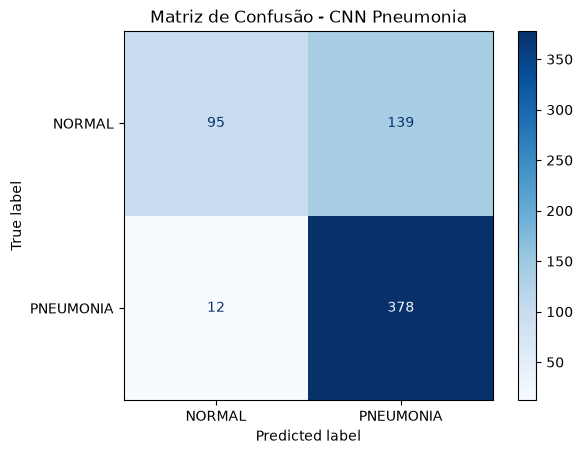


Relatório de classificação:
              precision    recall  f1-score   support

      NORMAL     0.8879    0.4060    0.5572       234
   PNEUMONIA     0.7311    0.9692    0.8335       390

    accuracy                         0.7580       624
   macro avg     0.8095    0.6876    0.6954       624
weighted avg     0.7899    0.7580    0.7299       624



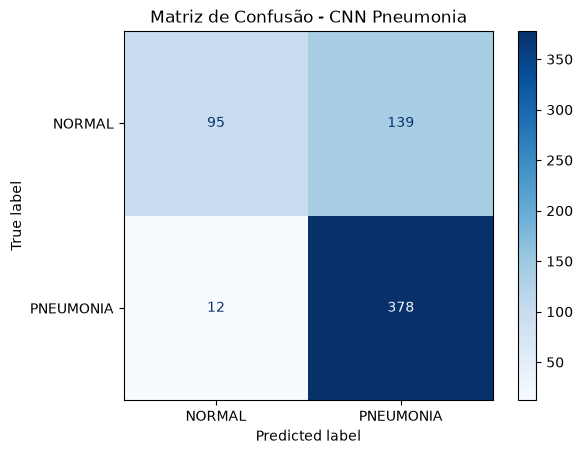


Relatório de classificação:
              precision    recall  f1-score   support

      NORMAL     0.8879    0.4060    0.5572       234
   PNEUMONIA     0.7311    0.9692    0.8335       390

    accuracy                         0.7580       624
   macro avg     0.8095    0.6876    0.6954       624
weighted avg     0.7899    0.7580    0.7299       624



In [190]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Matriz de confusão
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Exibir graficamente
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusão - CNN Pneumonia")
plt.show()

# Relatório de classificação
print("\nRelatório de classificação:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

Probabilidades médias:
NORMAL: 0.6082
PNEUMONIA: 0.9599

Medianas:
NORMAL: 0.7264
PNEUMONIA: 0.9973


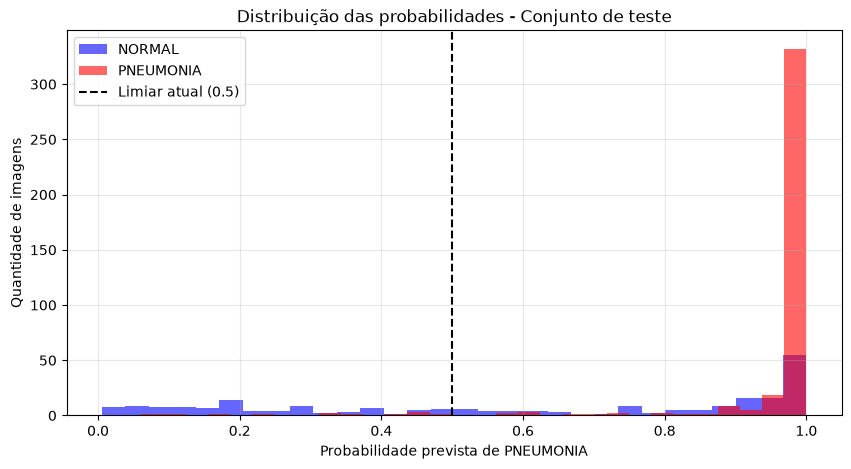

Probabilidades médias:
NORMAL: 0.6082
PNEUMONIA: 0.9599

Medianas:
NORMAL: 0.7264
PNEUMONIA: 0.9973


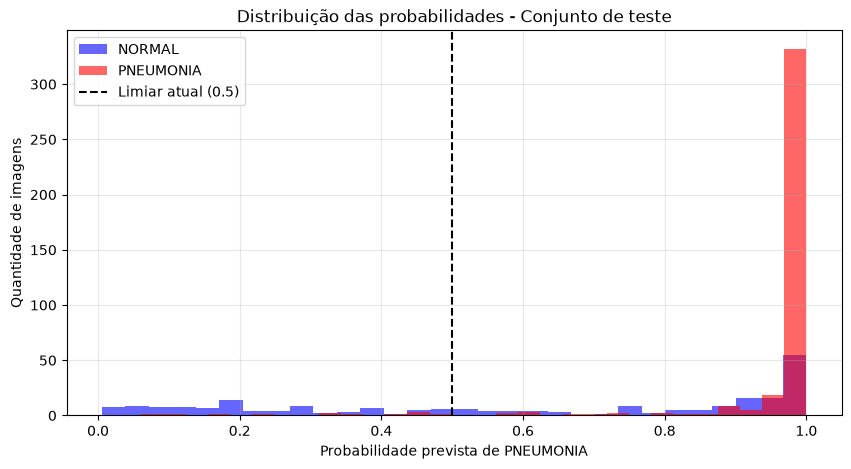

In [191]:
import numpy as np
import matplotlib.pyplot as plt

# Separar probabilidades por classe real
prob_normal = y_prob[y_true == 0]
prob_pneumonia = y_prob[y_true == 1]

print("Probabilidades médias:")
print(f"NORMAL: {prob_normal.mean():.4f}")
print(f"PNEUMONIA: {prob_pneumonia.mean():.4f}")

print("\nMedianas:")
print(f"NORMAL: {np.median(prob_normal):.4f}")
print(f"PNEUMONIA: {np.median(prob_pneumonia):.4f}")

# Histograma
plt.figure(figsize=(10, 5))

plt.hist(
    prob_normal,
    bins=30,
    alpha=0.6,
    label="NORMAL",
    color="blue"
)

plt.hist(
    prob_pneumonia,
    bins=30,
    alpha=0.6,
    label="PNEUMONIA",
    color="red"
)

plt.axvline(
    x=0.5,
    color="black",
    linestyle="--",
    label="Limiar atual (0.5)"
)

plt.xlabel("Probabilidade prevista de PNEUMONIA")
plt.ylabel("Quantidade de imagens")
plt.title("Distribuição das probabilidades - Conjunto de teste")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Entendendo os erros de classificação

Comparamos os resultados de **validação e teste** e examinamos radiografias NORMAL classificadas incorretamente como PNEUMONIA. Também visualizamos exemplos de imagens normais dos dois conjuntos.

Em seguida, medimos a **razão largura/altura** das imagens para investigar se diferenças de formato estão associadas aos erros. O objetivo aqui não é corrigir o modelo, mas **formular e examinar hipóteses** sobre seu comportamento.


In [192]:
import numpy as np
import pandas as pd

# Rótulos verdadeiros da validação
y_val_true = df_val["classe"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).to_numpy()

# Probabilidades previstas
y_val_prob = modelo_teste.predict(val_ds).ravel()

# Classificação utilizando limiar 0.5
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Separar probabilidades por classe
val_prob_normal = y_val_prob[y_val_true == 0]
val_prob_pneumonia = y_val_prob[y_val_true == 1]

print("VALIDAÇÃO")
print("-" * 45)

print("Total de imagens:", len(y_val_true))

print("\nProbabilidade média de pneumonia:")
print(f"NORMAL: {val_prob_normal.mean():.4f}")
print(f"PNEUMONIA: {val_prob_pneumonia.mean():.4f}")

print("\nMediana:")
print(f"NORMAL: {np.median(val_prob_normal):.4f}")
print(f"PNEUMONIA: {np.median(val_prob_pneumonia):.4f}")

print("\nDistribuição das previsões:")
print("NORMAL:", np.sum(y_val_pred == 0))
print("PNEUMONIA:", np.sum(y_val_pred == 1))

67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step
VALIDAÇÃO
---------------------------------------------
Total de imagens: 1058

Probabilidade média de pneumonia:
NORMAL: 0.1415
PNEUMONIA: 0.9277

Mediana:
NORMAL: 0.0543
PNEUMONIA: 0.9962

Distribuição das previsões:
NORMAL: 295
PNEUMONIA: 763


67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step
VALIDAÇÃO
---------------------------------------------
Total de imagens: 1058

Probabilidade média de pneumonia:
NORMAL: 0.1415
PNEUMONIA: 0.9277

Mediana:
NORMAL: 0.0543
PNEUMONIA: 0.9962

Distribuição das previsões:
NORMAL: 295
PNEUMONIA: 763


In [193]:
# Criar uma cópia do DataFrame de teste
df_resultados = df_test.copy()

# Adicionar probabilidades e previsões
df_resultados["probabilidade"] = y_prob
df_resultados["previsao"] = y_pred

# Selecionar imagens NORMAL classificadas como PNEUMONIA
df_falsos_positivos = df_resultados[
    (df_resultados["classe"] == "NORMAL") &
    (df_resultados["previsao"] == 1)
].copy()

# Ordenar pelas maiores probabilidades
df_falsos_positivos = df_falsos_positivos.sort_values(
    "probabilidade",
    ascending=False
)

print("Total de falsos positivos:", len(df_falsos_positivos))

display(
    df_falsos_positivos[
        ["arquivo", "probabilidade"]
    ].head(10)
)

Total de falsos positivos: 139


,arquivo,probabilidade
133,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999854
130,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999743
144,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999678
16,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999569
136,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999235
112,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998814
124,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998750
105,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998429
140,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998212
146,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998134


Total de falsos positivos: 139


,arquivo,probabilidade
133,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999854
130,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999743
144,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999678
16,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999569
136,/workspace/notebooks/pneumonia/dataset/chest_x...,0.999235
112,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998814
124,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998750
105,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998429
140,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998212
146,/workspace/notebooks/pneumonia/dataset/chest_x...,0.998134


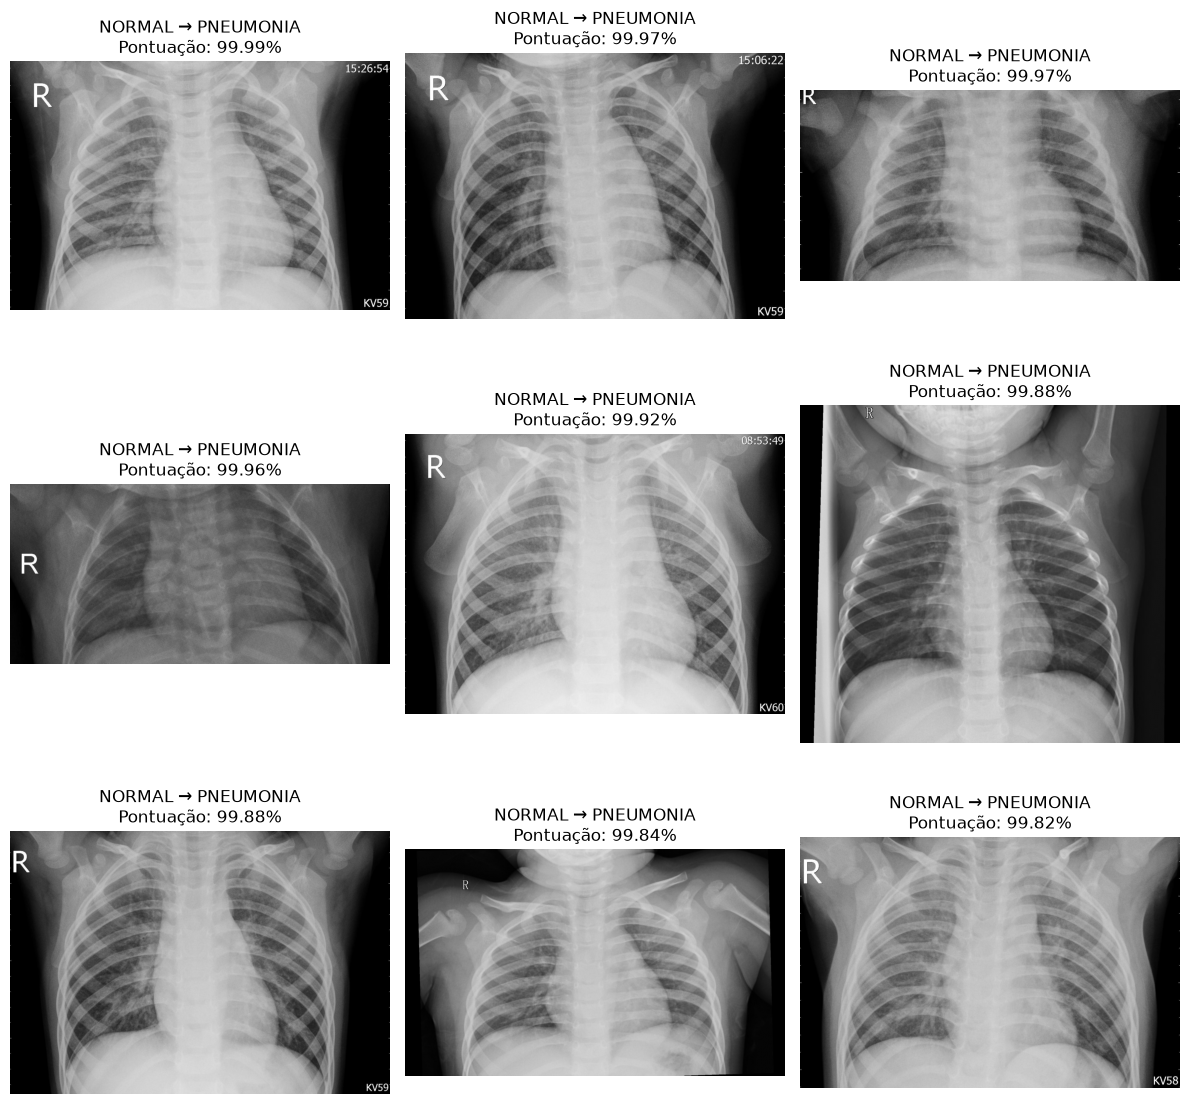

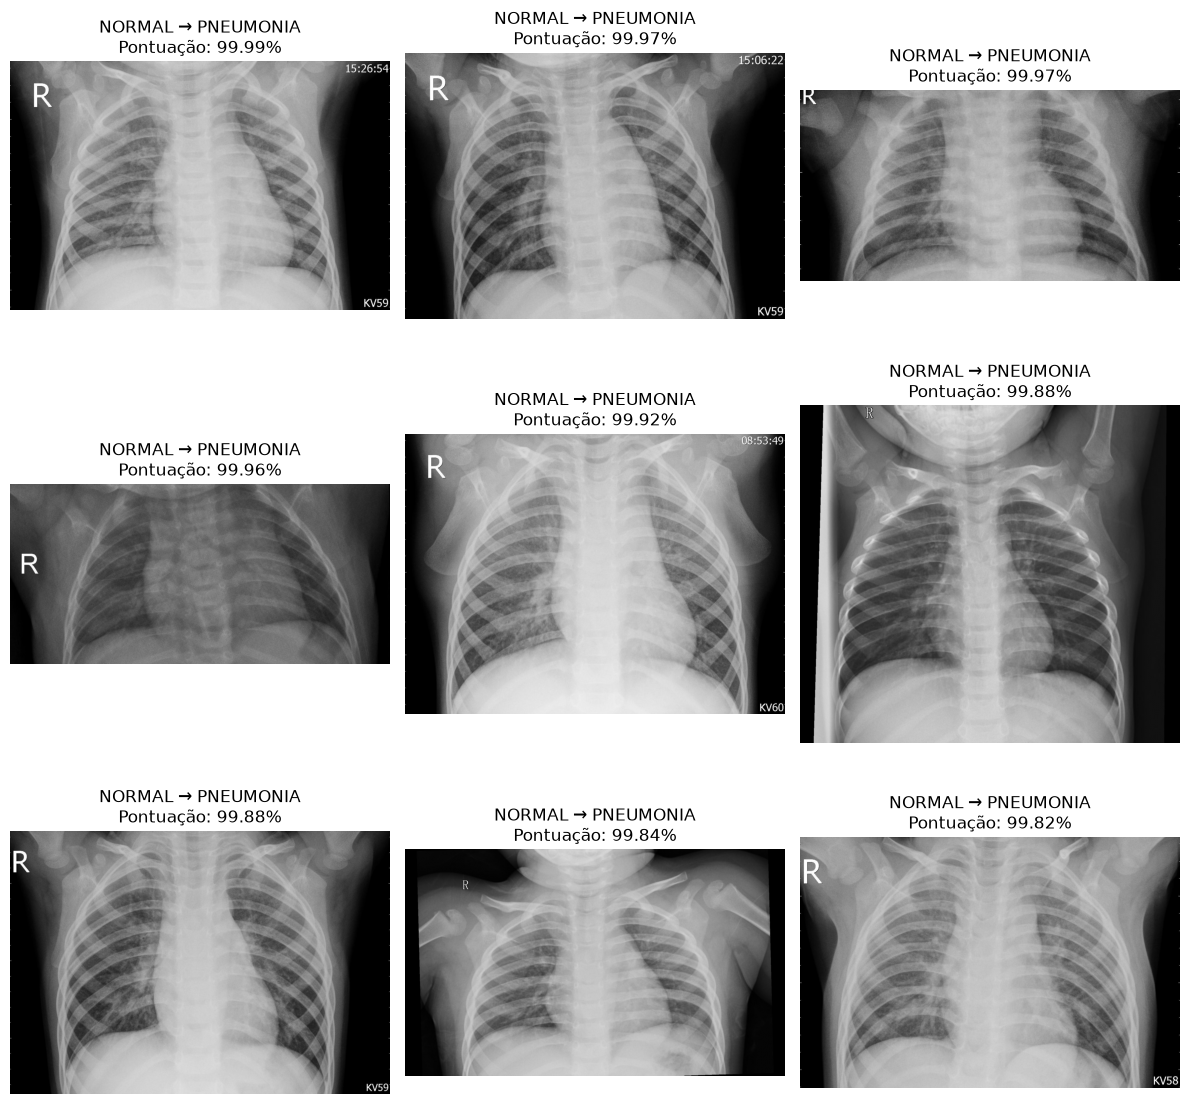

In [194]:
import matplotlib.pyplot as plt
from PIL import Image

# Selecionar os 9 falsos positivos com maiores pontuações
amostras = df_falsos_positivos.head(9)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (_, linha) in zip(axes.flat, amostras.iterrows()):

    imagem = Image.open(linha["arquivo"]).convert("L")

    ax.imshow(imagem, cmap="gray")

    ax.set_title(
        f"NORMAL → PNEUMONIA\n"
        f"Pontuação: {linha['probabilidade']:.2%}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

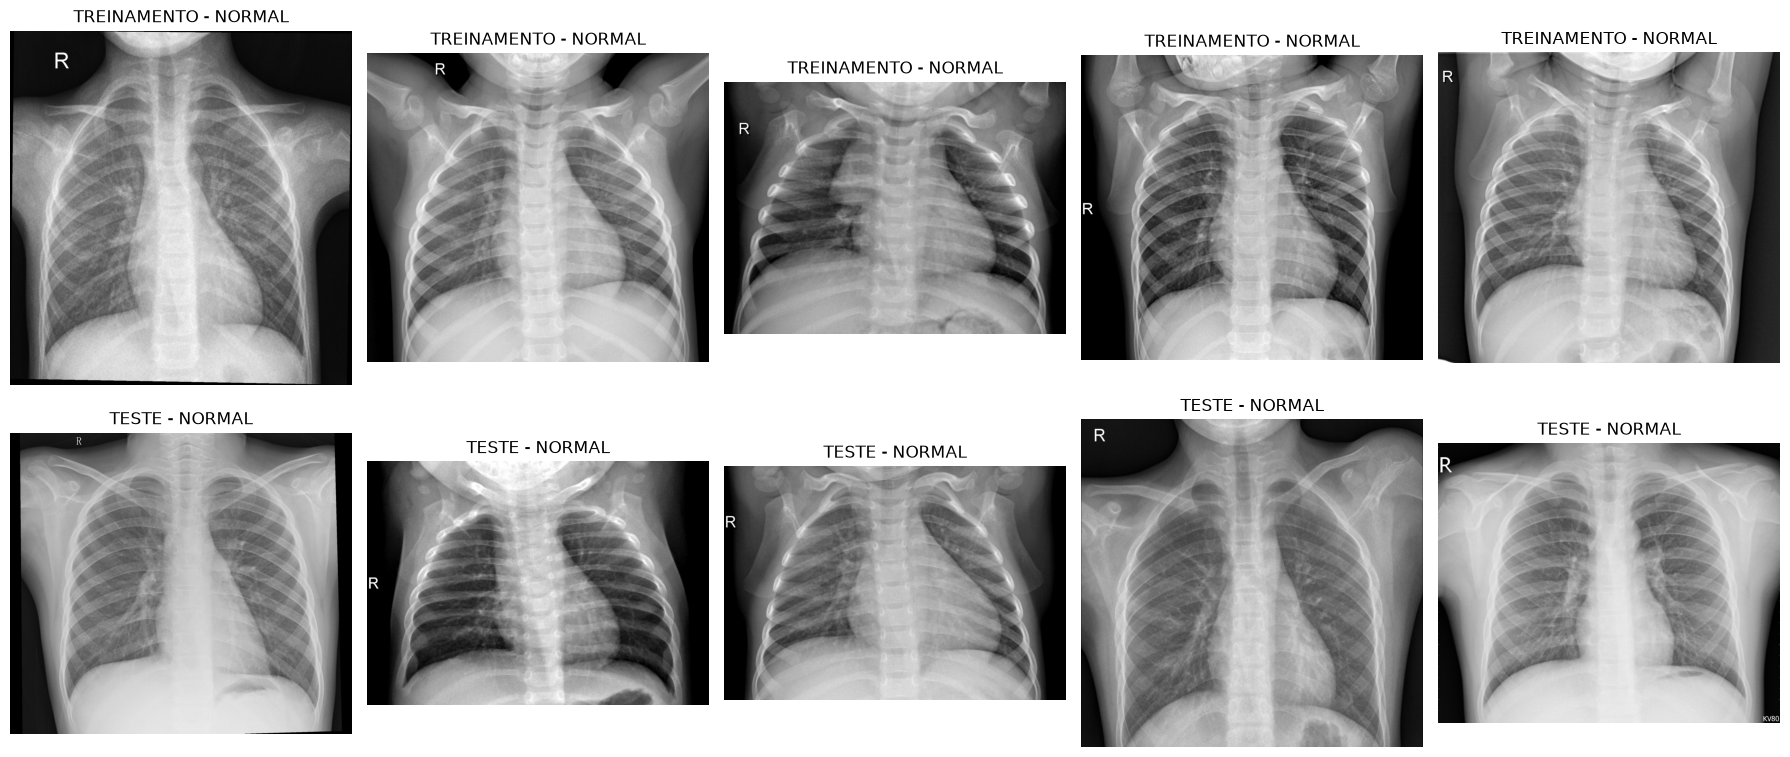

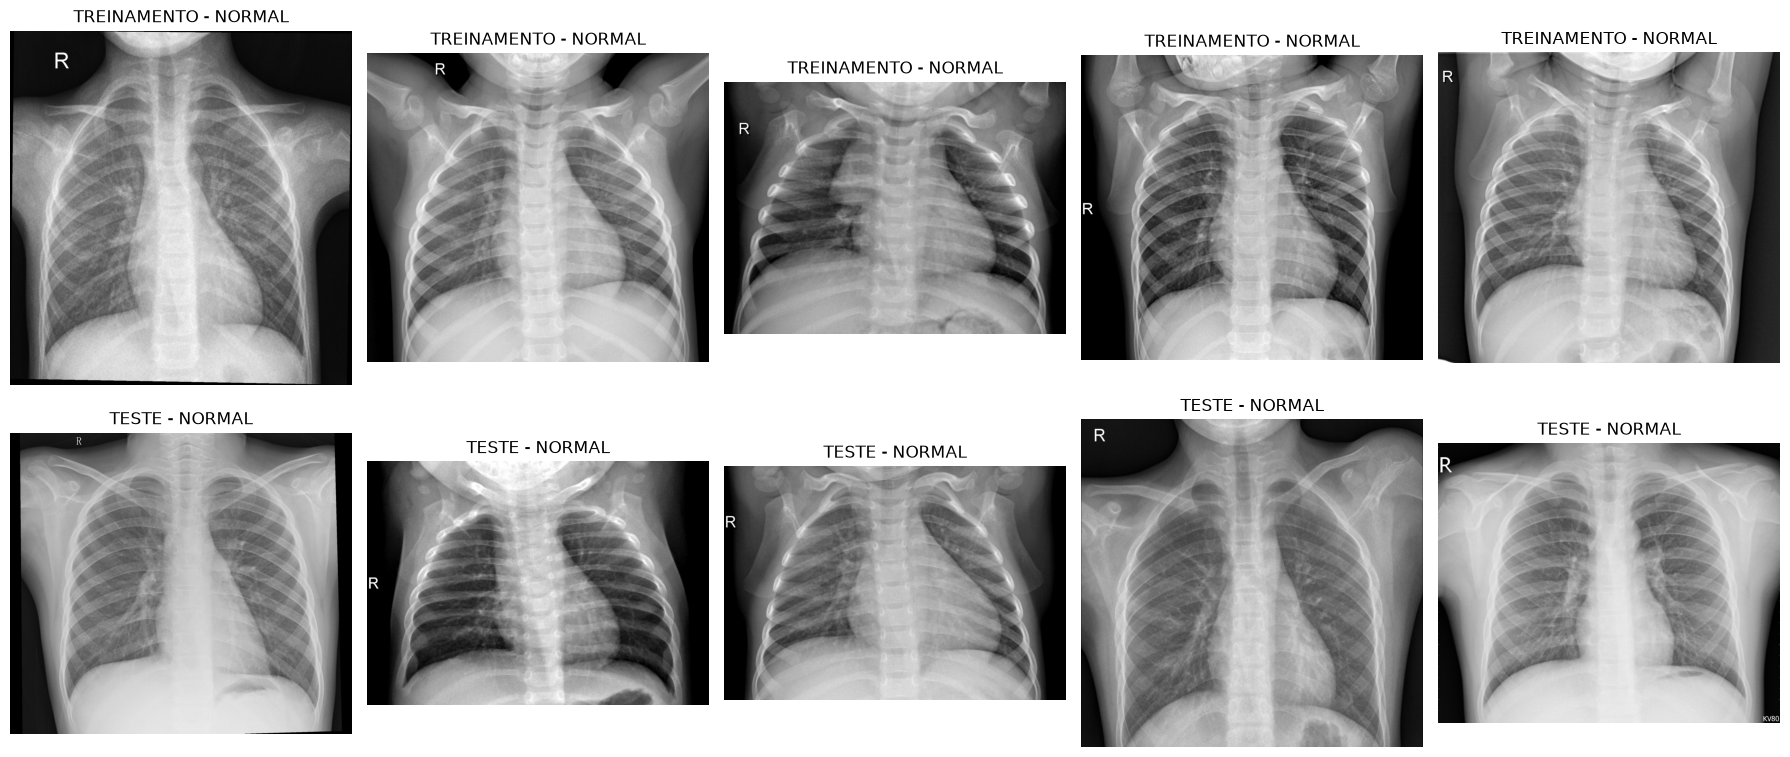

In [195]:
import matplotlib.pyplot as plt
from PIL import Image

# Selecionar imagens normais
normais_train = df_train[
    df_train["classe"] == "NORMAL"
].sample(n=5, random_state=42)

normais_test = df_test[
    df_test["classe"] == "NORMAL"
].sample(n=5, random_state=42)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

# Primeira linha: treinamento
for ax, (_, linha) in zip(axes[0], normais_train.iterrows()):

    imagem = Image.open(linha["arquivo"]).convert("L")

    ax.imshow(imagem, cmap="gray")
    ax.set_title("TREINAMENTO - NORMAL")
    ax.axis("off")

# Segunda linha: teste
for ax, (_, linha) in zip(axes[1], normais_test.iterrows()):

    imagem = Image.open(linha["arquivo"]).convert("L")

    ax.imshow(imagem, cmap="gray")
    ax.set_title("TESTE - NORMAL")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [196]:
import numpy as np
import pandas as pd
from PIL import Image

def analisar_imagens(df, conjunto):

    resultados = []

    df_normal = df[df["classe"] == "NORMAL"]

    for caminho in df_normal["arquivo"]:

        with Image.open(caminho) as img:

            largura, altura = img.size

            imagem_cinza = np.asarray(
                img.convert("L"),
                dtype=np.float32
            )

            resultados.append({
                "conjunto": conjunto,
                "largura": largura,
                "altura": altura,
                "proporcao": largura / altura,
                "brilho_medio": imagem_cinza.mean(),
                "contraste": imagem_cinza.std()
            })

    return pd.DataFrame(resultados)


# Analisar os três conjuntos
stats_train = analisar_imagens(df_train, "Treinamento")
stats_val = analisar_imagens(df_val, "Validação")
stats_test = analisar_imagens(df_test, "Teste")

# Reunir os resultados
df_stats = pd.concat(
    [stats_train, stats_val, stats_test],
    ignore_index=True
)

# Exibir estatísticas
resumo = df_stats.groupby("conjunto").agg({
    "largura": ["mean", "median"],
    "altura": ["mean", "median"],
    "proporcao": ["mean", "median"],
    "brilho_medio": ["mean", "median"],
    "contraste": ["mean", "median"]
})

display(resumo.round(2))

largura           altura         proporcao        brilho_medio  \
                mean  median     mean  median      mean median         mean   
conjunto                                                                      
Teste        1800.30  1762.0  1369.09  1317.5      1.37   1.35   124.070000   
Treinamento  1669.14  1638.0  1383.26  1329.0      1.23   1.22   122.440002   
Validação    1662.17  1656.0  1374.16  1316.0      1.23   1.23   122.129997   

                         contraste             
                 median       mean     median  
conjunto                                       
Teste        124.070000  60.169998  60.799999  
Treinamento  122.150002  61.330002  61.490002  
Validação    121.949997  61.840000  61.889999

largura           altura         proporcao        brilho_medio  \
                mean  median     mean  median      mean median         mean   
conjunto                                                                      
Teste        1800.30  1762.0  1369.09  1317.5      1.37   1.35   124.070000   
Treinamento  1669.14  1638.0  1383.26  1329.0      1.23   1.22   122.440002   
Validação    1662.17  1656.0  1374.16  1316.0      1.23   1.23   122.129997   

                         contraste             
                 median       mean     median  
conjunto                                       
Teste        124.070000  60.169998  60.799999  
Treinamento  122.150002  61.330002  61.490002  
Validação    121.949997  61.840000  61.889999

In [197]:
from PIL import Image
import pandas as pd

# Selecionar apenas imagens NORMAL do teste
df_normal_teste = df_resultados[
    df_resultados["classe"] == "NORMAL"
].copy()

# Calcular proporção original
def calcular_proporcao(caminho):
    with Image.open(caminho) as img:
        largura, altura = img.size
        return largura / altura

df_normal_teste["proporcao"] = (
    df_normal_teste["arquivo"].apply(calcular_proporcao)
)

# Identificar acertos e erros
df_normal_teste["resultado"] = df_normal_teste["previsao"].map({
    0: "NORMAL correto",
    1: "Falso positivo"
})

# Resumo
resumo_erros = df_normal_teste.groupby("resultado").agg(
    quantidade=("proporcao", "count"),
    proporcao_media=("proporcao", "mean"),
    proporcao_mediana=("proporcao", "median"),
    pontuacao_media=("probabilidade", "mean")
)

display(resumo_erros.round(4))

,quantidade,proporcao_media,proporcao_mediana,pontuacao_media
resultado,,,,
Falso positivo,139,1.4276,1.4182,0.8751
NORMAL correto,95,1.2811,1.2738,0.2177


,quantidade,proporcao_media,proporcao_mediana,pontuacao_media
resultado,,,,
Falso positivo,139,1.4276,1.4182,0.8751
NORMAL correto,95,1.2811,1.2738,0.2177


In [198]:
from PIL import Image
import pandas as pd

def obter_proporcao(caminho):
    with Image.open(caminho) as img:
        largura, altura = img.size
        return largura / altura

# Criar cópia para não alterar o DataFrame original
df_proporcoes = df_train.copy()

# Calcular proporção das imagens
df_proporcoes["proporcao"] = (
    df_proporcoes["arquivo"].apply(obter_proporcao)
)

# Comparar as duas classes
resumo_proporcoes = df_proporcoes.groupby("classe").agg(
    quantidade=("proporcao", "count"),
    proporcao_media=("proporcao", "mean"),
    proporcao_mediana=("proporcao", "median"),
    desvio_padrao=("proporcao", "std")
)

display(resumo_proporcoes.round(4))

,quantidade,proporcao_media,proporcao_mediana,desvio_padrao
classe,,,,
NORMAL,1071,1.2270,1.2227,0.1288
PNEUMONIA,3087,1.5166,1.4878,0.2536


,quantidade,proporcao_media,proporcao_mediana,desvio_padrao
classe,,,,
NORMAL,1071,1.2270,1.2227,0.1288
PNEUMONIA,3087,1.5166,1.4878,0.2536


## 7. Uma hipótese: a proporção da imagem influencia a previsão?

Treinamos uma **regressão logística usando somente a razão largura/altura** da radiografia. Se essa característica simples conseguir distinguir parcialmente as classes, ela pode representar um **atalho estatístico** disponível no conjunto de dados.

Também visualizamos como o redimensionamento com preenchimento altera a apresentação da imagem.

**Limite da análise:** encontrar associação entre geometria e rótulo **não prova** que a CNN utiliza essa característica nem que ela seja a causa dos falsos positivos.


In [199]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report
)

# Preparar treinamento
X_train_ratio = df_proporcoes[["proporcao"]]

y_train_ratio = df_proporcoes["classe"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
})

# Preparar validação
df_val_ratio = df_val.copy()

df_val_ratio["proporcao"] = (
    df_val_ratio["arquivo"].apply(obter_proporcao)
)

X_val_ratio = df_val_ratio[["proporcao"]]

y_val_ratio = df_val_ratio["classe"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
})

# Criar classificador simples
modelo_ratio = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Treinar usando apenas a proporção
modelo_ratio.fit(X_train_ratio, y_train_ratio)

# Prever na validação
y_val_ratio_prob = modelo_ratio.predict_proba(
    X_val_ratio
)[:, 1]

y_val_ratio_pred = (
    y_val_ratio_prob >= 0.5
).astype(int)

print("RESULTADOS - APENAS PROPORÇÃO")
print("-" * 45)

print(
    "Accuracy:",
    round(accuracy_score(y_val_ratio, y_val_ratio_pred), 4)
)

print(
    "AUC:",
    round(roc_auc_score(y_val_ratio, y_val_ratio_prob), 4)
)

print("\nRelatório de classificação:")

print(
    classification_report(
        y_val_ratio,
        y_val_ratio_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

RESULTADOS - APENAS PROPORÇÃO
---------------------------------------------
Accuracy: 0.7684
AUC: 0.8542

Relatório de classificação:
              precision    recall  f1-score   support

      NORMAL       0.53      0.81      0.64       270
   PNEUMONIA       0.92      0.75      0.83       788

    accuracy                           0.77      1058
   macro avg       0.73      0.78      0.74      1058
weighted avg       0.82      0.77      0.78      1058



RESULTADOS - APENAS PROPORÇÃO
---------------------------------------------
Accuracy: 0.7684
AUC: 0.8542

Relatório de classificação:
              precision    recall  f1-score   support

      NORMAL       0.53      0.81      0.64       270
   PNEUMONIA       0.92      0.75      0.83       788

    accuracy                           0.77      1058
   macro avg       0.73      0.78      0.74      1058
weighted avg       0.82      0.77      0.78      1058



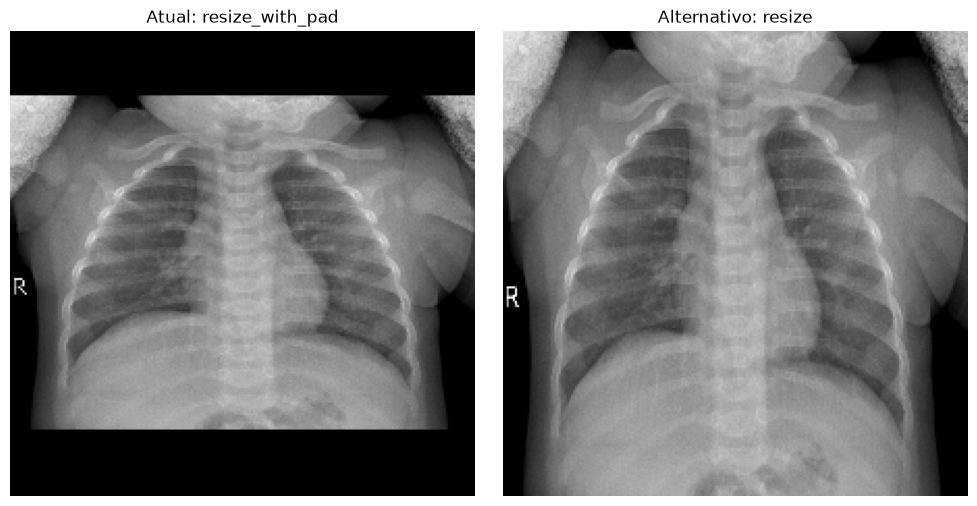

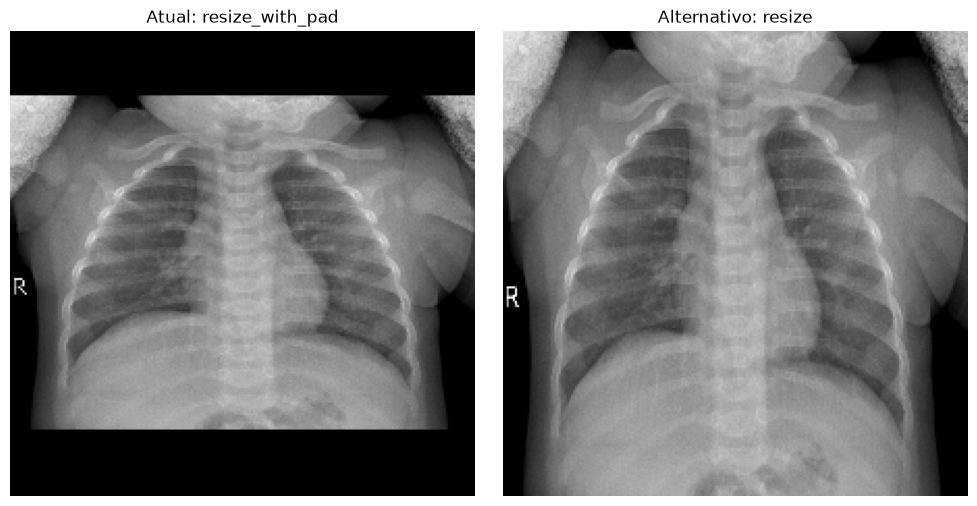

In [200]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Selecionar uma imagem de treinamento
caminho = df_train.iloc[0]["arquivo"]

# Ler e decodificar
imagem = tf.io.read_file(caminho)
imagem = tf.io.decode_jpeg(imagem, channels=1)
imagem = tf.image.convert_image_dtype(imagem, tf.float32)

# Método atual: preserva proporção
imagem_pad = tf.image.resize_with_pad(
    imagem,
    224,
    224
)

# Método alternativo: redimensionamento direto
imagem_resize = tf.image.resize(
    imagem,
    (224, 224)
)

# Comparação visual
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(imagem_pad.numpy().squeeze(), cmap="gray")
axes[0].set_title("Atual: resize_with_pad")
axes[0].axis("off")

axes[1].imshow(imagem_resize.numpy().squeeze(), cmap="gray")
axes[1].set_title("Alternativo: resize")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 8. Preparação das imagens — CNN 2

Criamos uma segunda versão do experimento, mantendo a proposta de classificação, mas substituindo `resize_with_pad` por **`tf.image.resize`**. Agora, todas as imagens são ajustadas diretamente para **224 × 224 pixels**, sem adicionar bordas de preenchimento.

Isso permite comparar o desempenho das duas estratégias. Entretanto, o redimensionamento direto **pode distorcer a proporção anatômica**; portanto, a comparação não isola apenas o efeito das bordas pretas.


In [201]:
import tensorflow as tf

def preprocessar_imagem_v2(caminho, classe):

    # Ler arquivo
    imagem = tf.io.read_file(caminho)

    # Decodificar JPEG em escala de cinza
    imagem = tf.io.decode_jpeg(
        imagem,
        channels=1
    )

    # Converter pixels para float32 entre 0 e 1
    imagem = tf.image.convert_image_dtype(
        imagem,
        tf.float32
    )

    # Redimensionar diretamente para 224x224
    imagem = tf.image.resize(
        imagem,
        (224, 224)
    )

    # Garantir o formato esperado
    imagem = tf.ensure_shape(
        imagem,
        (224, 224, 1)
    )

    return imagem, classe

In [202]:
# Selecionar uma imagem de treinamento
caminho = df_train.iloc[0]["arquivo"]

# Classe correspondente
classe = 0 if df_train.iloc[0]["classe"] == "NORMAL" else 1

# Processar
imagem_v2, classe_v2 = preprocessar_imagem_v2(
    caminho,
    classe
)

print("Formato:", imagem_v2.shape)
print("Tipo:", imagem_v2.dtype)
print("Valor mínimo:", float(tf.reduce_min(imagem_v2)))
print("Valor máximo:", float(tf.reduce_max(imagem_v2)))
print("Classe:", classe_v2)

Formato: (224, 224, 1)
Tipo: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 1.0
Classe: 0


Formato: (224, 224, 1)
Tipo: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 1.0
Classe: 0


In [203]:
import tensorflow as tf

BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def criar_dataset_v2(df, treinamento=False):

    # Caminhos das imagens
    caminhos = df["arquivo"].astype(str).to_numpy()

    # Converter classes em números
    classes = df["classe"].map({
        "NORMAL": 0,
        "PNEUMONIA": 1
    }).astype("float32").to_numpy()

    # Criar dataset
    dataset = tf.data.Dataset.from_tensor_slices(
        (caminhos, classes)
    )

    # Embaralhar somente durante o treinamento
    if treinamento:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

    # Aplicar o novo pré-processamento
    dataset = dataset.map(
        preprocessar_imagem_v2,
        num_parallel_calls=AUTOTUNE
    )

    # Agrupar imagens em batches
    dataset = dataset.batch(BATCH_SIZE)

    # Otimizar carregamento
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Criar os datasets do Experimento 2
train_ds_v2 = criar_dataset_v2(
    df_train,
    treinamento=True
)

val_ds_v2 = criar_dataset_v2(
    df_val,
    treinamento=False
)

print("Datasets do Experimento 2 criados com sucesso!")

Datasets do Experimento 2 criados com sucesso!


Datasets do Experimento 2 criados com sucesso!


In [204]:
print("TREINAMENTO")

for imagens, classes in train_ds_v2.take(1):
    print("Formato das imagens:", imagens.shape)
    print("Formato das classes:", classes.shape)
    print("Valor mínimo:", float(tf.reduce_min(imagens)))
    print("Valor máximo:", float(tf.reduce_max(imagens)))


print("\nVALIDAÇÃO")

for imagens, classes in val_ds_v2.take(1):
    print("Formato das imagens:", imagens.shape)
    print("Formato das classes:", classes.shape)
    print("Valor mínimo:", float(tf.reduce_min(imagens)))
    print("Valor máximo:", float(tf.reduce_max(imagens)))

TREINAMENTO
Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)
Valor mínimo: 0.0
Valor máximo: 1.0

VALIDAÇÃO
Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)
Valor mínimo: 0.0
Valor máximo: 1.0


TREINAMENTO
Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)
Valor mínimo: 0.0
Valor máximo: 1.0

VALIDAÇÃO
Formato das imagens: (16, 224, 224, 1)
Formato das classes: (16,)
Valor mínimo: 0.0
Valor máximo: 1.0


## 8.1. Arquitetura e treinamento — CNN 2

A segunda CNN mantém a **mesma arquitetura geral** e os critérios de treinamento da primeira, incluindo pesos de classe, monitoramento da perda de validação e parada antecipada. Assim, a principal diferença experimental está na **forma de redimensionar as imagens**.

O melhor modelo é salvo em `modelos/cnn_pneumonia_v2_resize.keras`. Quando `TREINAR_MODELOS = False`, ele é carregado do disco, sem repetir as épocas de treinamento.


In [205]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Definir uma semente para melhorar a reprodutibilidade
tf.keras.utils.set_random_seed(42)

# Criar a segunda CNN
modelo_v2 = models.Sequential([

    layers.Input(shape=(224, 224, 1)),

    # Primeiro bloco convolucional
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Segundo bloco convolucional
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Terceiro bloco convolucional
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Extração das características
    layers.GlobalAveragePooling2D(),

    # Classificação
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Saída binária
    layers.Dense(1, activation="sigmoid")

])

modelo_v2.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [206]:
modelo_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("CNN 2 compilada com sucesso!")

CNN 2 compilada com sucesso!


CNN 2 compilada com sucesso!


In [207]:
from pathlib import Path
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Pasta onde salvaremos os modelos
MODELOS_DIR = BASE_DIR / "modelos"

MODELOS_DIR.mkdir(parents=True, exist_ok=True)

# Nome exclusivo para a CNN 2
CAMINHO_MODELO_V2 = MODELOS_DIR / "cnn_pneumonia_v2_resize.keras"

# Salvar o modelo com menor perda de validação
checkpoint_v2 = ModelCheckpoint(
    filepath=str(CAMINHO_MODELO_V2),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Interromper caso não haja melhora por 5 épocas
early_stopping_v2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

callbacks_v2 = [
    checkpoint_v2,
    early_stopping_v2
]

print("Callbacks da CNN 2 configurados com sucesso!")
print("Modelo será salvo em:", CAMINHO_MODELO_V2)

Callbacks da CNN 2 configurados com sucesso!
Modelo será salvo em: /workspace/notebooks/pneumonia/modelos/cnn_pneumonia_v2_resize.keras


Callbacks da CNN 2 configurados com sucesso!
Modelo será salvo em: /workspace/notebooks/pneumonia/modelos/cnn_pneumonia_v2_resize.keras


In [208]:
if TREINAR_MODELOS:
    historico_v2 = modelo_v2.fit(
        train_ds_v2, validation_data=val_ds_v2, epochs=15,
        class_weight=class_weights, callbacks=callbacks_v2
    )
    modelo_v2 = tf.keras.models.load_model(str(CAMINHO_MODELO_V2))
else:
    if not CAMINHO_MODELO_V2.exists():
        raise FileNotFoundError(f"Modelo CNN 2 não encontrado: {CAMINHO_MODELO_V2}")
    modelo_v2 = tf.keras.models.load_model(str(CAMINHO_MODELO_V2))
    historico_v2 = None
    print("CNN 2 carregada; treinamento dispensado.")

CNN 2 carregada; treinamento dispensado.


CNN 2 carregada; treinamento dispensado.


## 9. Comparação das CNNs na validação

Avaliamos as **duas CNNs no mesmo conjunto de validação**, usando o pré-processamento correspondente a cada uma: `resize_with_pad` na CNN 1 e `resize` na CNN 2.

As matrizes de confusão abaixo aparecem **lado a lado** e mostram quantas radiografias NORMAL e PNEUMONIA foram classificadas corretamente ou incorretamente. **Linhas** representam a classe real e **colunas**, a previsão do modelo.

Essa visualização complementa as métricas de acurácia, sensibilidade e especificidade: modelos com desempenho geral semelhante podem cometer tipos diferentes de erro. A comparação numérica consolidada aparece nas conclusões.


67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step


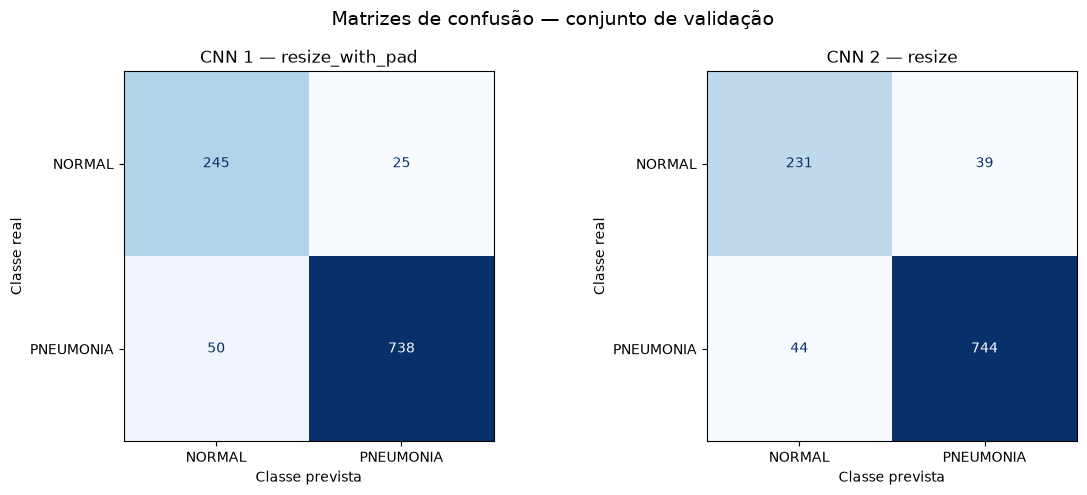


Relatório de classificação — CNN 2
              precision    recall  f1-score   support

      NORMAL     0.8400    0.8556    0.8477       270
   PNEUMONIA     0.9502    0.9442    0.9472       788

    accuracy                         0.9216      1058
   macro avg     0.8951    0.8999    0.8974      1058
weighted avg     0.9221    0.9216    0.9218      1058



67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step


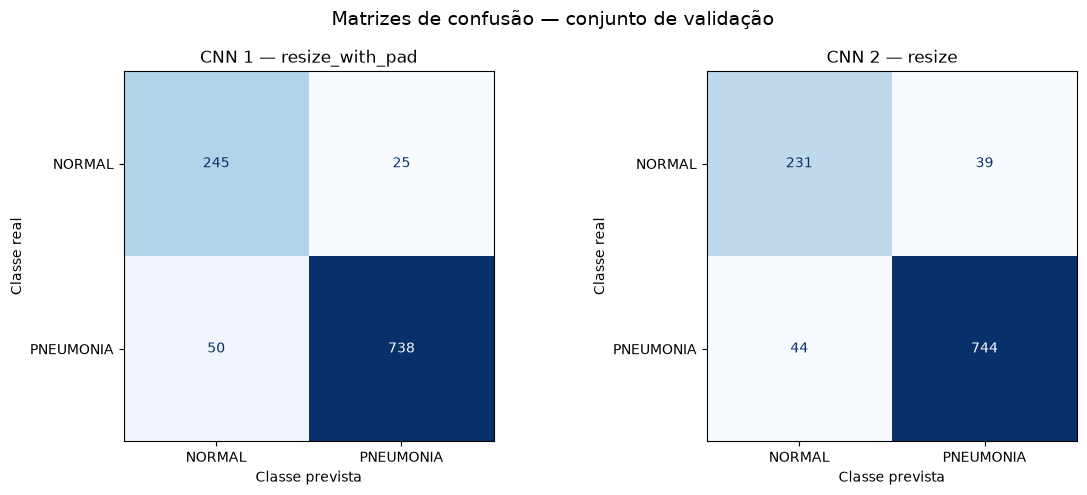


Relatório de classificação — CNN 2
              precision    recall  f1-score   support

      NORMAL     0.8400    0.8556    0.8477       270
   PNEUMONIA     0.9502    0.9442    0.9472       788

    accuracy                         0.9216      1058
   macro avg     0.8951    0.8999    0.8974      1058
weighted avg     0.9221    0.9216    0.9218      1058



In [209]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Mesmo conjunto de validação para as duas CNNs
y_val_true = df_val["classe"].map({
    "NORMAL": 0,
    "PNEUMONIA": 1
}).to_numpy()

# CNN 1: modelo salvo e imagens com resize_with_pad (val_ds)
modelo_v1 = tf.keras.models.load_model(str(CAMINHO_MODELO))
y_val_prob_v1 = modelo_v1.predict(val_ds).ravel()
y_val_pred_v1 = (y_val_prob_v1 >= 0.5).astype(int)

# CNN 2: imagens com resize convencional (val_ds_v2)
# Carregar os melhores pesos salvos, inclusive quando TREINAR_MODELOS=False
modelo_v2_avaliacao = tf.keras.models.load_model(str(CAMINHO_MODELO_V2))
y_val_prob_v2 = modelo_v2_avaliacao.predict(val_ds_v2).ravel()
y_val_pred_v2 = (y_val_prob_v2 >= 0.5).astype(int)

cm_v1 = confusion_matrix(y_val_true, y_val_pred_v1, labels=[0, 1])
cm_v2 = confusion_matrix(y_val_true, y_val_pred_v2, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cm, titulo in [
    (axes[0], cm_v1, "CNN 1 — resize_with_pad"),
    (axes[1], cm_v2, "CNN 2 — resize"),
]:
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["NORMAL", "PNEUMONIA"]
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(titulo)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

fig.suptitle("Matrizes de confusão — conjunto de validação", fontsize=14)
plt.tight_layout()
plt.show()

print("\nRelatório de classificação — CNN 2")
print(classification_report(
    y_val_true, y_val_pred_v2,
    labels=[0, 1], target_names=["NORMAL", "PNEUMONIA"],
    digits=4, zero_division=0
))


In [210]:
# As previsões e a matriz da CNN 1 já foram calculadas na célula anterior.
print("Matriz de confusão — CNN 1")
print(cm_v1)

print("\nRelatório de classificação — CNN 1")
print(classification_report(
    y_val_true, y_val_pred_v1,
    labels=[0, 1], target_names=["NORMAL", "PNEUMONIA"],
    digits=4, zero_division=0
))

tn, fp, fn, tp = cm_v1.ravel()
especificidade_v1 = tn / (tn + fp) if (tn + fp) else float("nan")
print(f"\nEspecificidade CNN 1: {especificidade_v1:.2%}")


Matriz de confusão — CNN 1
[[245  25]
 [ 50 738]]

Relatório de classificação — CNN 1
              precision    recall  f1-score   support

      NORMAL     0.8305    0.9074    0.8673       270
   PNEUMONIA     0.9672    0.9365    0.9516       788

    accuracy                         0.9291      1058
   macro avg     0.8989    0.9220    0.9095      1058
weighted avg     0.9323    0.9291    0.9301      1058


Especificidade CNN 1: 90.74%


Matriz de confusão — CNN 1
[[245  25]
 [ 50 738]]

Relatório de classificação — CNN 1
              precision    recall  f1-score   support

      NORMAL     0.8305    0.9074    0.8673       270
   PNEUMONIA     0.9672    0.9365    0.9516       788

    accuracy                         0.9291      1058
   macro avg     0.8989    0.9220    0.9095      1058
weighted avg     0.9323    0.9291    0.9301      1058


Especificidade CNN 1: 90.74%


## 10. Investigação exploratória no teste

Para entender melhor os **falsos positivos da CNN 1**, analisamos as radiografias NORMAL do teste por faixas da razão largura/altura. Calculamos a frequência de erros em cada faixa e a **correlação de Spearman** entre a proporção da imagem e a probabilidade prevista de PNEUMONIA.

Esses resultados ajudam a verificar se existe uma **associação estatística** entre geometria e previsão. Como o conjunto de teste foi examinado nessa investigação, ele **não deve ser reutilizado como avaliação independente** após eventuais ajustes orientados por esses achados.


In [211]:
import pandas as pd
import numpy as np
from PIL import Image

# Criar um DataFrame para análise
df_analise = df_test.copy().reset_index(drop=True)

# Adicionar as previsões da CNN 1
df_analise["classe_real"] = y_true
df_analise["prob_pneumonia"] = y_prob
df_analise["classe_prevista"] = y_pred

# Função para calcular a proporção original da imagem
def calcular_proporcao(caminho):
    with Image.open(caminho) as imagem:
        largura, altura = imagem.size

    return largura / altura

# Calcular a proporção de cada radiografia
df_analise["proporcao"] = df_analise["arquivo"].apply(
    calcular_proporcao
)

# Selecionar somente as radiografias normais
df_normais = df_analise[
    df_analise["classe_real"] == 0
].copy()

# Identificar os falsos positivos
df_normais["falso_positivo"] = (
    df_normais["classe_prevista"] == 1
).astype(int)

# Conferir os resultados
print("Total de imagens normais:", len(df_normais))

print(
    "Normais classificadas corretamente:",
    (df_normais["falso_positivo"] == 0).sum()
)

print(
    "Normais classificadas como pneumonia:",
    df_normais["falso_positivo"].sum()
)

print(
    "\nProporção média das imagens normais:",
    round(df_normais["proporcao"].mean(), 4)
)

Total de imagens normais: 234
Normais classificadas corretamente: 95
Normais classificadas como pneumonia: 139

Proporção média das imagens normais: 1.3681


Total de imagens normais: 234
Normais classificadas corretamente: 95
Normais classificadas como pneumonia: 139

Proporção média das imagens normais: 1.3681


In [212]:
import pandas as pd
import numpy as np

# Definir as faixas de proporção
faixas = [0, 1.2, 1.3, 1.4, 1.5, np.inf]

nomes_faixas = [
    "< 1.20",
    "1.20 - 1.30",
    "1.30 - 1.40",
    "1.40 - 1.50",
    ">= 1.50"
]

# Classificar cada imagem em uma faixa
df_normais["faixa_proporcao"] = pd.cut(
    df_normais["proporcao"],
    bins=faixas,
    labels=nomes_faixas,
    right=False
)

# Agrupar os resultados
resultado_faixas = (
    df_normais
    .groupby("faixa_proporcao", observed=False)
    .agg(
        total_imagens=("falso_positivo", "size"),
        falsos_positivos=("falso_positivo", "sum"),
        taxa_falsos_positivos=("falso_positivo", "mean"),
        prob_media_pneumonia=("prob_pneumonia", "mean")
    )
    .reset_index()
)

# Converter taxas para porcentagem
resultado_faixas["taxa_falsos_positivos"] *= 100
resultado_faixas["prob_media_pneumonia"] *= 100

# Exibir tabela
print("\nANÁLISE DAS IMAGENS NORMAIS POR PROPORÇÃO\n")

print(
    resultado_faixas.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


ANÁLISE DAS IMAGENS NORMAIS POR PROPORÇÃO

faixa_proporcao  total_imagens  falsos_positivos  taxa_falsos_positivos  prob_media_pneumonia
         < 1.20             54                22                  40.74                 43.22
    1.20 - 1.30             44                24                  54.55                 54.99
    1.30 - 1.40             41                18                  43.90                 52.46
    1.40 - 1.50             32                22                  68.75                 70.76
        >= 1.50             63                53                  84.13                 80.38



ANÁLISE DAS IMAGENS NORMAIS POR PROPORÇÃO

faixa_proporcao  total_imagens  falsos_positivos  taxa_falsos_positivos  prob_media_pneumonia
         < 1.20             54                22                  40.74                 43.22
    1.20 - 1.30             44                24                  54.55                 54.99
    1.30 - 1.40             41                18                  43.90                 52.46
    1.40 - 1.50             32                22                  68.75                 70.76
        >= 1.50             63                53                  84.13                 80.38


In [213]:
from scipy.stats import spearmanr

# Correlação entre proporção e probabilidade de pneumonia
correlacao, p_valor = spearmanr(
    df_normais["proporcao"],
    df_normais["prob_pneumonia"]
)

print("CORRELAÇÃO DE SPEARMAN")
print("----------------------")

print(f"Correlação: {correlacao:.4f}")
print(f"Valor-p: {p_valor:.6g}")

print("\nQuantidade de imagens:", len(df_normais))

CORRELAÇÃO DE SPEARMAN
----------------------
Correlação: 0.4264
Valor-p: 9.3452e-12

Quantidade de imagens: 234


CORRELAÇÃO DE SPEARMAN
----------------------
Correlação: 0.4264
Valor-p: 9.3452e-12

Quantidade de imagens: 234


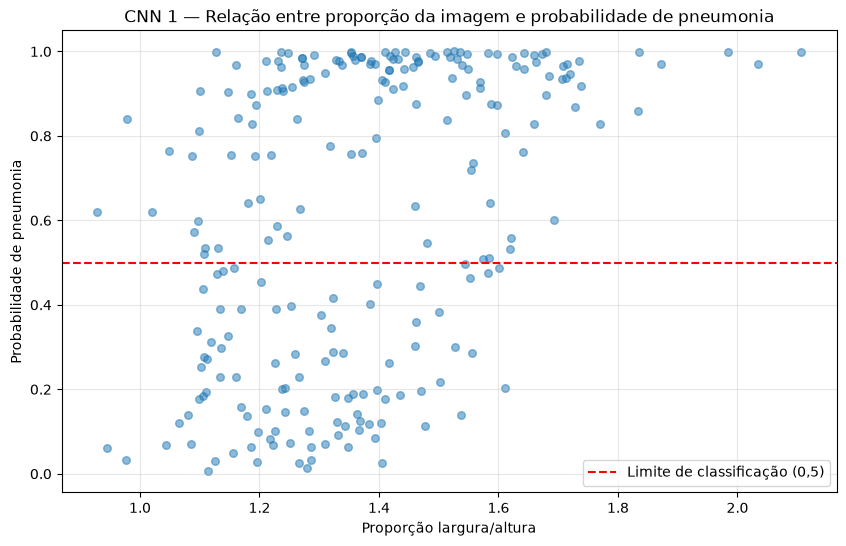

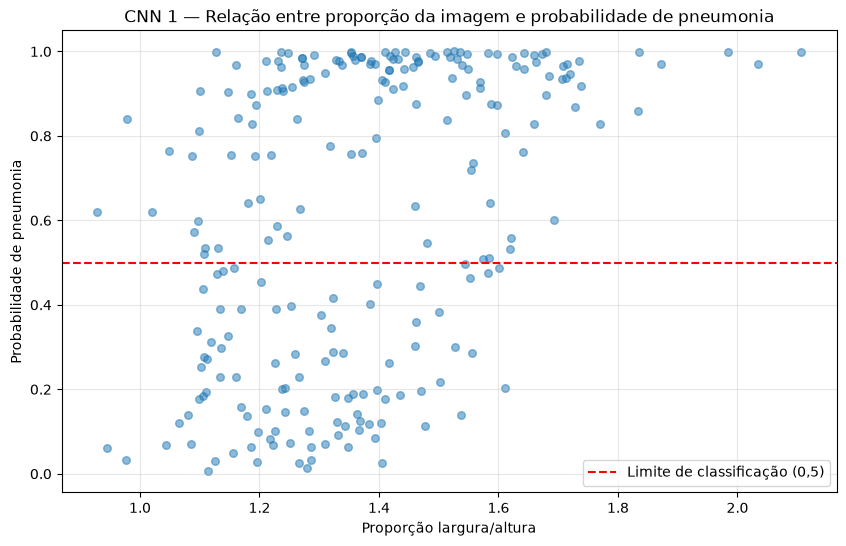

In [214]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df_normais["proporcao"],
    df_normais["prob_pneumonia"],
    alpha=0.5,
    s=30
)

# Limite de decisão da CNN
plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    label="Limite de classificação (0,5)"
)

plt.xlabel("Proporção largura/altura")
plt.ylabel("Probabilidade de pneumonia")
plt.title(
    "CNN 1 — Relação entre proporção da imagem "
    "e probabilidade de pneumonia"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Experimento ilustrativo: escala e preenchimento

Selecionamos uma radiografia NORMAL classificada incorretamente e comparamos a previsão original com outra versão da mesma imagem, na qual **reduzimos a região da radiografia e aumentamos o preenchimento**.

A proposta é observar a **sensibilidade da previsão a mudanças visuais**. Como escala e preenchimento são alterados ao mesmo tempo e apenas uma imagem é examinada, o resultado **não permite concluir** qual fator causou a mudança nem generalizá-la para todo o dataset.


In [215]:
# Selecionar radiografias normais classificadas incorretamente
df_erros = df_normais[
    df_normais["falso_positivo"] == 1
].copy()

# Calcular a distância em relação à proporção 1.50
df_erros["distancia"] = abs(
    df_erros["proporcao"] - 1.50
)

# Selecionar a imagem mais próxima de 1.50
imagem_selecionada = (
    df_erros
    .sort_values("distancia")
    .iloc[0]
)

print("Imagem selecionada:")
print("Arquivo:", imagem_selecionada["arquivo"])
print("Proporção:", round(imagem_selecionada["proporcao"], 4))

print(
    "Probabilidade de pneumonia:",
    f'{imagem_selecionada["prob_pneumonia"]:.2%}'
)

Imagem selecionada:
Arquivo: /workspace/notebooks/pneumonia/dataset/chest_xray/test/NORMAL/NORMAL2-IM-0251-0001.jpeg
Proporção: 1.4932
Probabilidade de pneumonia: 98.92%


Imagem selecionada:
Arquivo: /workspace/notebooks/pneumonia/dataset/chest_xray/test/NORMAL/NORMAL2-IM-0251-0001.jpeg
Proporção: 1.4932
Probabilidade de pneumonia: 98.92%


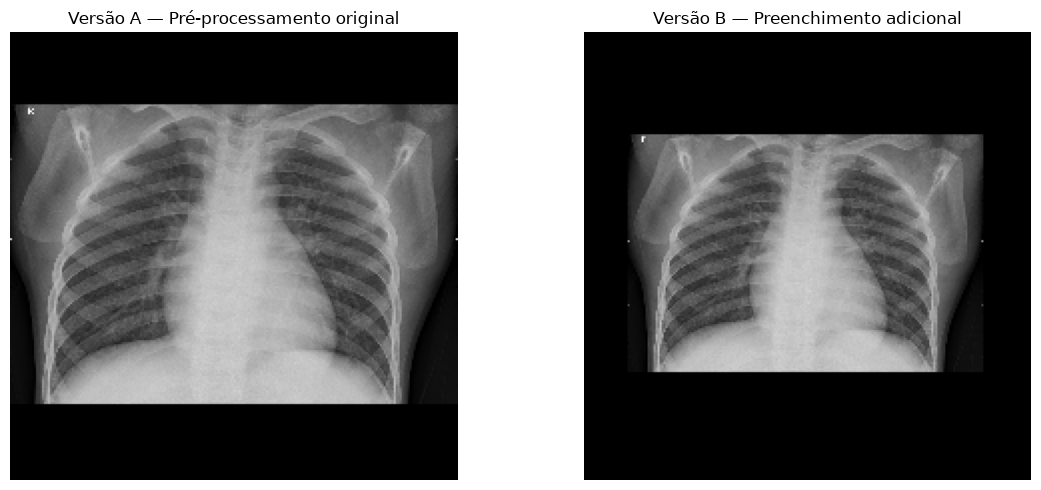

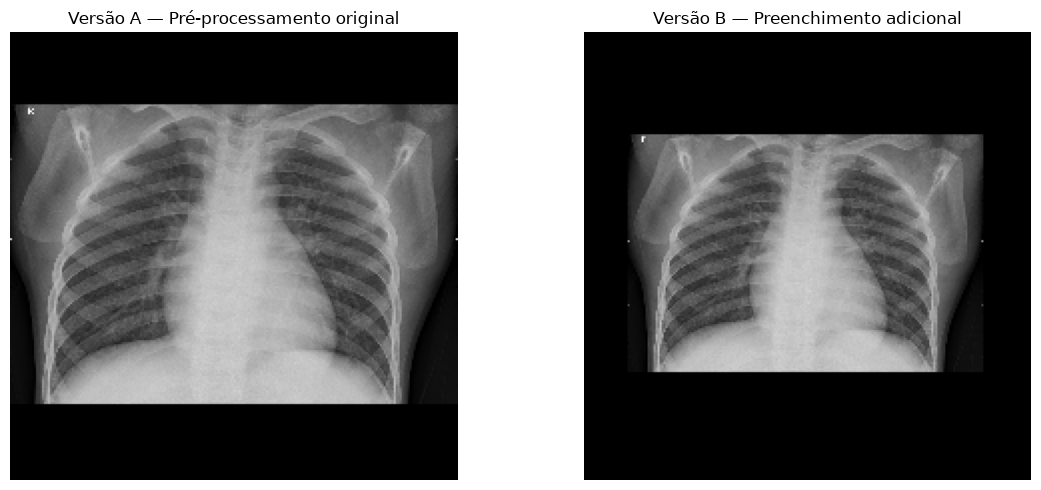

In [216]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Caminho da imagem selecionada
caminho = imagem_selecionada["arquivo"]

# Carregar a imagem
imagem = tf.io.read_file(caminho)
imagem = tf.io.decode_jpeg(imagem, channels=1)
imagem = tf.image.convert_image_dtype(imagem, tf.float32)

# VERSÃO A: pré-processamento original da CNN 1
imagem_a = tf.image.resize_with_pad(
    imagem,
    224,
    224
)

# VERSÃO B: imagem reduzida e centralizada
imagem_b = tf.image.resize_with_pad(
    imagem,
    179,
    179
)

# Adicionar preenchimento até 224 x 224
imagem_b = tf.image.resize_with_crop_or_pad(
    imagem_b,
    224,
    224
)

# Visualizar as duas versões
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(imagem_a.numpy().squeeze(), cmap="gray")
axes[0].set_title("Versão A — Pré-processamento original")
axes[0].axis("off")

axes[1].imshow(imagem_b.numpy().squeeze(), cmap="gray")
axes[1].set_title("Versão B — Preenchimento adicional")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [217]:
import numpy as np

# Adicionar dimensão do batch
entrada_a = tf.expand_dims(imagem_a, axis=0)
entrada_b = tf.expand_dims(imagem_b, axis=0)

# Fazer as previsões com a CNN 1
prob_a = float(modelo_v1.predict(entrada_a, verbose=0)[0][0])
prob_b = float(modelo_v1.predict(entrada_b, verbose=0)[0][0])

# Calcular a diferença
diferenca = (prob_b - prob_a) * 100

print("COMPARAÇÃO DAS PREVISÕES - CNN 1")
print("--------------------------------")

print(f"Versão A (original): {prob_a:.2%}")
print(f"Versão B (padding adicional): {prob_b:.2%}")

print(f"\nDiferença: {diferenca:+.2f} pontos percentuais")

print("\nCLASSIFICAÇÕES")

print(
    "Versão A:",
    "PNEUMONIA" if prob_a >= 0.5 else "NORMAL"
)

print(
    "Versão B:",
    "PNEUMONIA" if prob_b >= 0.5 else "NORMAL"
)

COMPARAÇÃO DAS PREVISÕES - CNN 1
--------------------------------
Versão A (original): 98.92%
Versão B (padding adicional): 99.96%

Diferença: +1.04 pontos percentuais

CLASSIFICAÇÕES
Versão A: PNEUMONIA
Versão B: PNEUMONIA


COMPARAÇÃO DAS PREVISÕES - CNN 1
--------------------------------
Versão A (original): 98.92%
Versão B (padding adicional): 99.96%

Diferença: +1.04 pontos percentuais

CLASSIFICAÇÕES
Versão A: PNEUMONIA
Versão B: PNEUMONIA


## 12. Resultados e conclusões

### Comparação na validação

| Indicador | CNN 1 (`resize_with_pad`) | CNN 2 (`resize`) |
|---|---:|---:|
| Acurácia | **92,91%** | 92,16% |
| Sensibilidade para PNEUMONIA | 93,65% | **94,42%** |
| Especificidade para NORMAL | **90,74%** | 85,56% |
| AUC | **98,19%** | 96,49% |

A **CNN 1 apresentou os melhores resultados gerais de validação**, embora a CNN 2 tenha alcançado sensibilidade ligeiramente maior para PNEUMONIA.

### O que aconteceu no teste?

Na CNN 1, a acurácia caiu para **75,80%**. A sensibilidade para PNEUMONIA foi de **96,92%**, mas a especificidade para NORMAL ficou em **40,60%**. A matriz de confusão `[[95, 139], [12, 378]]` mostra **139 imagens normais classificadas incorretamente como pneumonia**.

**Principal aprendizado:** uma validação com bons indicadores **não garante** o mesmo desempenho em dados com características diferentes.

### O que investigamos sobre os erros?

- No treinamento, a razão média largura/altura foi aproximadamente **1,227** para NORMAL e **1,517** para PNEUMONIA; entre as imagens NORMAL do teste, foi **1,368**.
- Uma regressão logística usando apenas essa razão alcançou **AUC de validação próxima de 0,854**, indicando que a geometria contém informação associada às classes neste dataset.
- Entre as imagens NORMAL do teste, a correlação de Spearman entre proporção e probabilidade de PNEUMONIA foi **ρ = 0,4264** (**p ≈ 9,35 × 10⁻¹²**). As faixas de maior proporção também apresentaram mais falsos positivos.
- Em uma imagem ilustrativa, a probabilidade de PNEUMONIA passou de **98,92% para 99,96%** após reduzir a radiografia e aumentar o preenchimento.

Esses achados são **compatíveis com a hipótese de *shortcut learning*** — quando um modelo se apoia em pistas indiretas do dataset —, mas **não comprovam a causa dos erros**. A CNN 2 também não superou a CNN 1 na validação; como seu redimensionamento altera a geometria, não podemos atribuir a diferença exclusivamente ao padding.

### Limitações e próximos passos

O conjunto de teste foi usado em análises exploratórias, e não realizamos experimentos causais que separem completamente os efeitos de **escala, proporção, preenchimento e origem das imagens**. Como continuidade, seriam úteis uma avaliação externa independente e testes controlados de pré-processamento.

**Conclusão:** desenvolvemos e comparamos duas CNNs para classificação de radiografias e demonstramos a importância de avaliar **generalização, erros por classe e possíveis vieses do dataset**, além da acurácia.

> **Uso exclusivamente acadêmico:** os modelos não foram validados para diagnóstico médico.
